In [ ]:
#We developed a predictive model for diabetes risk assessment, focusing on demographic and clinical factors. Demographic attributes (age, gender) and clinical markers (creatinine, HBA1C, BMI) are the factors we considered in model development.
#We developed the predictive model using Random Forest algorithm and Naive Bayes algorithm.
#The objective is to determine the predictive power of these variables and their potential impact on occurance of diabetes.
#The decision outcome of each patient was whether the patient was Non-diabetic, Potential Diabetic or Diabetic.
#For the decision outcome we labelled Non-diabetic as (1), Potential Diabetic as (2) and Diabetic as (3) in the CLASS NUMERICAL column.

In [ ]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier #Random Forest algorithm library
from sklearn.naive_bayes import GaussianNB          #Naive Bayes algorithm library
from sklearn.metrics import classification_report, accuracy_score
from sklearn.preprocessing import LabelEncoder      #to convert categorical data to numerical data
from sklearn.metrics import confusion_matrix
import seaborn as sns                               #for data visualization as heatmap
import matplotlib.pyplot as plt                     #for chart plotting the data

In [ ]:
# Function to plot confusion matrix
def plot_confusion_matrix(cm, class_names, title='Confusion Matrix'):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(title)
    plt.show()

In [8]:
# Importing the required dataset
df = pd.read_csv("/content/data_antibiotic_without_prescription (1).csv")

In [ ]:
# Transform the 'CLASS NUMERICAL' column to strings
df['CLASS NUMERICAL'] = df['CLASS NUMERICAL'].map({1: 'Non Diabetic', 2: 'Potential Diabetic', 3: 'Diabetic'})

In [ ]:
# Define feature/attribute columns and target column
features = ["Gender", "AGE", "Cr", "HbA1c", "BMI"]
target = "CLASS NUMERICAL"

In [ ]:
# Encoding categorical features ('Gender' is categorical) to numerical data
df['Gender'] = LabelEncoder().fit_transform(df['Gender'])

In [ ]:
# Split the dataset into features (X) and target (y)
X = df[features]
y = df[target]

In [ ]:
# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
#random_state is taken 42 to ensure reproducibility of results. It sets the seed for random numer generator.
#we used stratified sampling method.

In [ ]:
# Random Forest Model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)

In [ ]:
# Evaluating Random Forest Model
print("Random Forest Model")
print("Accuracy:", accuracy_score(y_test, rf_predictions))
print("Classification Report:\n", classification_report(y_test, rf_predictions))

Random Forest Model
Accuracy: 0.975
Classification Report:
                     precision    recall  f1-score   support

          Diabetic       1.00      0.97      0.98       169
      Non Diabetic       0.80      1.00      0.89        20
Potential Diabetic       1.00      1.00      1.00        11

          accuracy                           0.97       200
         macro avg       0.93      0.99      0.96       200
      weighted avg       0.98      0.97      0.98       200



Random Forest Confusion Matrix


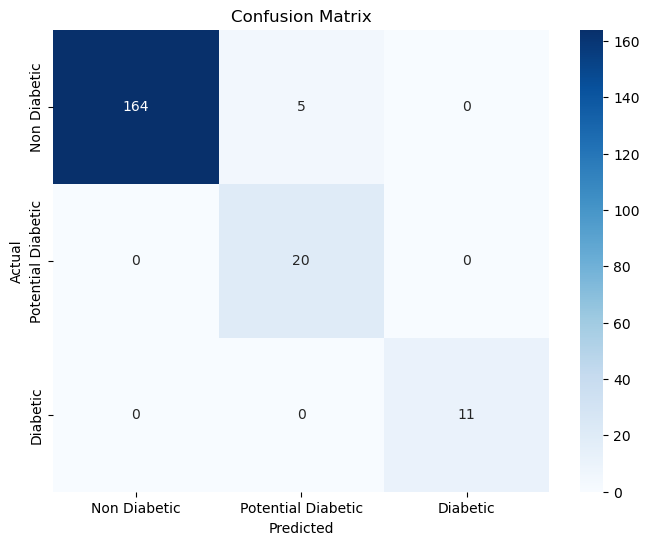

In [ ]:
# Preparing confusion matrix for Random Forest model
rf_cm = confusion_matrix(y_test, rf_predictions)
print("Random Forest Confusion Matrix")
plot_confusion_matrix(rf_cm, class_names=['Non Diabetic', 'Potential Diabetic', 'Diabetic'])

In [ ]:
# Naive Bayes Model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_predictions = nb_model.predict(X_test)

In [ ]:
# Evaluating Naive Bayes Model
print("\nNaive Bayes Model")
print("Accuracy:", accuracy_score(y_test, nb_predictions))
print("Classification Report:\n", classification_report(y_test, nb_predictions))


Naive Bayes Model
Accuracy: 0.925
Classification Report:
                     precision    recall  f1-score   support

          Diabetic       0.98      0.93      0.96       169
      Non Diabetic       0.60      0.90      0.72        20
Potential Diabetic       1.00      0.82      0.90        11

          accuracy                           0.93       200
         macro avg       0.86      0.88      0.86       200
      weighted avg       0.94      0.93      0.93       200



Naive Bayes Confusion Matrix


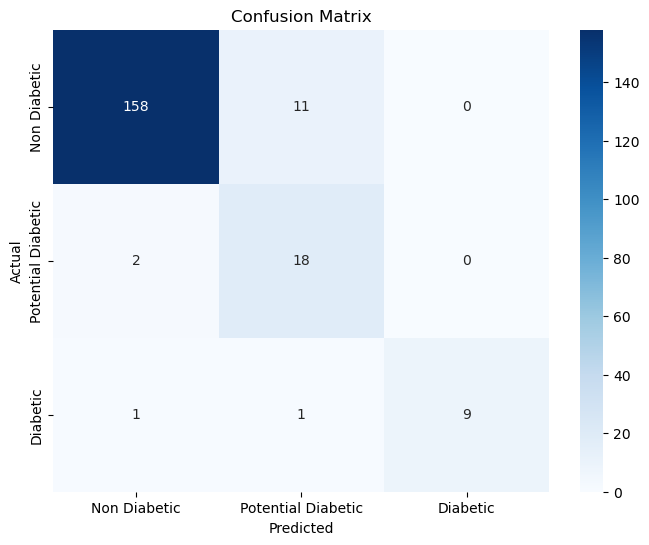

In [ ]:
# Preparing confusion matrix for Naive Bayes model
nb_cm = confusion_matrix(y_test, nb_predictions)
print("Naive Bayes Confusion Matrix")
plot_confusion_matrix(nb_cm, class_names=['Non Diabetic', 'Potential Diabetic', 'Diabetic'])